# 04 — Weibull AFT: C-MAPSS FD001

See `docs/project_brief.md` Section 4: mechanical wear-out is physically
well-modeled by a Weibull hazard function, and — unlike Cox PH — a fully
parametric model gives RUL **quantiles** directly, which is what
the deployment requirement ("RUL + confidence") actually needs. This
notebook derives the Weibull survival/hazard/log-likelihood by hand, then
fits with `lifelines`.

This notebook:
1. Derives the Weibull survival function, hazard function, and AFT
   log-likelihood from first principles
2. Validates that derivation with a from-scratch MLE fit, checked against
   `lifelines.WeibullFitter` on the same data -- once on the project's
   training labels (all failures) and once on a censored version, so both
   terms of the likelihood are tested
3. Fits the full covariate-regression AFT model (same feature set and
   engine-level split as Phase 3, for direct comparability)
4. Extracts the shape parameter, and tests the wear-out claim properly on
   per-engine lifetimes
5. Reports concordance index
6. Generates median RUL + 90% confidence intervals on the real test engines
   and checks empirical coverage — the first working version of "RUL +
   confidence," which is what Phase 8's API will actually serve


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from lifelines import WeibullFitter, WeibullAFTFitter

sys.path.append(str(Path("..") / "src"))
from turbofan_rul import data_loading, features, labeling, models, plotting

plotting.style()
SUBSET = "FD001"
CAP = 125
DATA_DIR = Path("..") / "data" / "raw"
PROCESSED_DIR = Path("..") / "data" / "processed"
MODELS_DIR = Path("..") / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Derivation: Weibull survival function, hazard, and AFT log-likelihood

**Survival function.** A Weibull-distributed time-to-failure $T$ with scale
$\lambda > 0$ and shape $\rho > 0$ has survival function

$$S(t) = P(T > t) = \exp\left[-\left(\frac{t}{\lambda}\right)^{\rho}\right]$$

**Density and hazard.** The density is $f(t) = -S'(t)$:

$$f(t) = \frac{\rho}{\lambda}\left(\frac{t}{\lambda}\right)^{\rho - 1} \exp\left[-\left(\frac{t}{\lambda}\right)^{\rho}\right]$$

and the hazard function $h(t) = f(t) / S(t)$ simplifies to

$$h(t) = \frac{\rho}{\lambda}\left(\frac{t}{\lambda}\right)^{\rho - 1}$$

The shape parameter $\rho$ entirely determines how the instantaneous
failure risk evolves over an engine's life:

- $\rho < 1$: decreasing hazard (infant mortality / early-failure-dominated)
- $\rho = 1$: constant hazard (memoryless, exponential distribution — no
  wear-out at all)
- $\rho > 1$: **increasing** hazard — the physically expected regime for
  mechanical wear-out, where risk accelerates as an engine ages

Fitting $\rho$ from data and checking whether it comes out $>1$ is therefore
a direct, checkable prediction of the "this is a wear-out process" framing
in the project brief — not just an assumption taken on faith.

**Accelerated Failure Time (AFT) parameterization.** Covariates $x$ enter
through the scale parameter on a log-linear scale:

$$\log \lambda(x) = x^\top \beta \quad\Longleftrightarrow\quad \lambda(x) = \exp(x^\top \beta)$$

This is what makes it an *accelerated* failure time model: covariates don't
change the *shape* of the hazard curve, they stretch or compress the time
axis it's plotted against by the multiplicative factor $\exp(x^\top\beta)$.
A covariate with $\beta > 0$ *increases* $\lambda$ (increases expected
survival time — protective); $\beta < 0$ decreases it (accelerates time
toward failure).

**Log-likelihood.** For $n$ observations with duration $t_i$ and event
indicator $\delta_i$ (1 = failure observed, 0 = censored — see
`labeling.py`), using $f(t) = h(t)\,S(t)$:

$$\ell(\lambda, \rho) = \sum_{i=1}^n \Big[\delta_i \log h(t_i) + \log S(t_i)\Big]
= \sum_{i=1}^n \left[\delta_i\left(\log\rho - \log\lambda_i + (\rho-1)(\log t_i - \log\lambda_i)\right) - \left(\frac{t_i}{\lambda_i}\right)^{\rho}\right]$$

A censored observation ($\delta_i=0$) contributes only its $\log S(t_i)$
term — exactly the mechanism, spelled out in closed form, by which this
model correctly uses "known to have survived at least this long" data
without ever needing to know the censored unit's true failure time. This is
the mathematical form of the censoring-handling argument from
`docs/project_brief.md` Section 1.

## 2. Validate the derivation: from-scratch MLE vs. `lifelines`

Fitting an **intercept-only** Weibull (no covariates — just the population-level
$\lambda,\rho$) by directly maximizing the log-likelihood derived above,
implemented with nothing but `numpy`/`scipy.optimize`, then checking it against
`lifelines.WeibullFitter` fit on the identical data. Agreement here is the
evidence that the derivation above is actually correct, not just plausible-looking
algebra.

In [2]:
data_loading.download_cmapss(SUBSET, data_dir=DATA_DIR)
cmapss = data_loading.load_subset(SUBSET, data_dir=DATA_DIR)
kept_sensors = features.load_kept_sensors(PROCESSED_DIR / f"{SUBSET.lower()}_sensor_selection.json")

train_survival = labeling.build_train_survival_frame(cmapss.train, cap=CAP)
train_survival = features.build_feature_matrix(train_survival, kept_sensors=kept_sensors)

# Weibull requires strictly positive durations; a handful of rows have RUL=0
# (an engine's final observed cycle). Nudging by a fixed small epsilon is
# standard practice here and applied identically wherever duration is used
# below, so it can't quietly bias one fit relative to another.
DURATION_EPS = 1e-3
durations = train_survival["duration"].values.astype(float) + DURATION_EPS
events = train_survival["event"].values.astype(float)


def weibull_neg_log_likelihood(log_params, t, delta):
    """Negative log-likelihood for an intercept-only Weibull, exactly the
    formula derived above. Parameters are optimized in log-space so lambda
    and rho stay positive without needing constrained optimization."""
    log_lam, log_rho = log_params
    lam, rho = np.exp(log_lam), np.exp(log_rho)
    log_hazard = np.log(rho) - np.log(lam) + (rho - 1) * (np.log(t) - np.log(lam))
    log_survival = -(t / lam) ** rho
    log_lik = delta * log_hazard + log_survival
    return -np.sum(log_lik)


x0 = [np.log(50.0), np.log(1.5)]
result = minimize(weibull_neg_log_likelihood, x0, args=(durations, events),
                   method="Nelder-Mead", options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 10000})
lambda_scratch, rho_scratch = np.exp(result.x)

wf = WeibullFitter().fit(durations, event_observed=events)

print(f"{'':20s}{'lambda':>12s}{'rho':>12s}{'neg log-lik':>16s}")
print(f"{'from-scratch MLE':20s}{lambda_scratch:12.4f}{rho_scratch:12.4f}{result.fun:16.2f}")
print(f"{'lifelines':20s}{wf.lambda_:12.4f}{wf.rho_:12.4f}{-wf.log_likelihood_:16.2f}")

rel_diff_lambda = abs(lambda_scratch - wf.lambda_) / wf.lambda_
rel_diff_rho = abs(rho_scratch - wf.rho_) / wf.rho_
print(f"\nrelative difference: lambda={rel_diff_lambda:.2e}, rho={rel_diff_rho:.2e}")
assert rel_diff_lambda < 1e-3 and rel_diff_rho < 1e-3, "from-scratch fit disagrees with lifelines -- derivation likely has a bug"
print("OK: from-scratch derivation matches lifelines to within numerical tolerance.")

# The project's training labels are all event=1, so the check above only
# exercises the failure term. Repeat it on the censored encoding
# (rows beyond the cap -> event=0) to validate the censoring term too.
censored = labeling.build_train_survival_frame(cmapss.train, cap=CAP, censor_above_cap=True)
t_c = censored["duration"].values.astype(float) + DURATION_EPS
d_c = censored["event"].values.astype(float)
res_c = minimize(weibull_neg_log_likelihood, x0, args=(t_c, d_c),
                 method="Nelder-Mead", options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 10000})
lam_c, rho_c = np.exp(res_c.x)
wf_c = WeibullFitter().fit(t_c, event_observed=d_c)
rel_c = max(abs(lam_c - wf_c.lambda_) / wf_c.lambda_, abs(rho_c - wf_c.rho_) / wf_c.rho_)
print(f"\nWith censoring ({int((d_c == 0).sum())} censored rows): max relative difference = {rel_c:.2e}")
assert rel_c < 1e-3, "censored-term derivation disagrees with lifelines"
print("OK: the censoring term of the derivation matches lifelines too.")

                          lambda         rho     neg log-lik
from-scratch MLE         95.5777      1.8990       108490.48
lifelines                95.5777      1.8990       108490.48

relative difference: lambda=2.44e-07, rho=5.35e-07
OK: from-scratch derivation matches lifelines to within numerical tolerance.



With censoring (8031 censored rows): max relative difference = 4.56e-07
OK: the censoring term of the derivation matches lifelines too.


**What this fitted $\rho$ does and doesn't show.** The durations fitted
above are *row-level remaining lives*: every cycle of every engine is a
separate row, with remaining life capped at 125. That distribution mostly
reflects how the labels are built -- each engine contributes one row per
remaining cycle, and every row above the cap is piled up at exactly 125 --
not how long engines actually last. So $\rho$ here is a property of the
label construction and should **not** be read as evidence of wear-out.

The physically meaningful test is a Weibull fit to **per-engine total
lifetimes** -- one number per engine, the cycle at which it failed. That's
done in Section 4, alongside the covariate model's $\rho$.

## 3. Fit the covariate-regression AFT model

Same engine-level train/validation split and the same curated 25-feature
subset as Phase 3's Cox model (`random_state=42` reproduces the identical
20 held-out engines) — direct comparability between models is the point of
keeping the split and feature set fixed across the model ladder, not an
oversight. A ridge penalizer is applied for the same collinearity reason as
Cox PH (see `models.py`).

lifelines' `WeibullAFTFitter` has no option to cluster standard errors by
engine (unlike Cox in Phase 3), so the p-values and confidence intervals in
Sections 4-5 treat ~17k correlated rows from 80 engines as independent and
are far too narrow. Read the coefficients by sign and size, not by p-value.
Predictions and the 90% prediction intervals don't depend on these standard
errors.

In [3]:
aft_train_df, aft_val_df = models.train_val_split_by_engine(
    train_survival, val_fraction=0.2, random_state=42
)

aft_feature_cols = ["cycle_count"]
for sensor in kept_sensors:
    aft_feature_cols += [f"{sensor}_roll15_mean", f"{sensor}_roll15_slope"]

aft_train_scaled, aft_val_scaled, aft_scaler = models.standardize_features(
    aft_train_df, aft_val_df, aft_feature_cols
)

aft_fit_df = aft_train_scaled.copy()
aft_fit_df["duration"] = aft_fit_df["duration"] + DURATION_EPS

aft_model = WeibullAFTFitter(penalizer=0.1)
aft_model.fit(aft_fit_df[aft_feature_cols + ["duration", "event"]],
              duration_col="duration", event_col="event")
models.save_model(aft_model, MODELS_DIR / "weibull_aft_fd001.joblib")
print("Fit complete.")

Fit complete.


## 4. Shape parameter

Two different $\rho$'s, answering two different questions:
- the covariate model's $\rho$ describes the shape of the remaining-life
  distribution it predicts *for a given set of sensor features* -- it's what
  sets the width and skew of the deployed intervals;
- a Weibull fit to **per-engine total lifetimes** (one value per training
  engine, every engine observed to failure) is the direct test of whether
  these engines wear out, i.e. whether failure risk rises with age.

In [4]:
rho_row = aft_model.summary.loc["rho_"].iloc[0]
rho_hat = rho_row["exp(coef)"]
print(f"Covariate AFT model shape parameter (rho): {rho_hat:.3f}  "
      f"(95% CI [{rho_row['exp(coef) lower 95%']:.3f}, {rho_row['exp(coef) upper 95%']:.3f}], "
      f"too narrow -- treats correlated rows as independent)")

# The wear-out test: one lifetime per engine, all observed to failure.
lifetimes = cmapss.train.groupby("unit_number")["time_cycles"].max().values
wf_life = WeibullFitter().fit(lifetimes, event_observed=np.ones(len(lifetimes)))
rho_lo, rho_hi = wf_life.summary.loc["rho_", ["coef lower 95%", "coef upper 95%"]]
print(f"\nPer-engine lifetime Weibull fit ({len(lifetimes)} engines): rho = {wf_life.rho_:.3f}, "
      f"95% CI [{rho_lo:.3f}, {rho_hi:.3f}]")

if rho_lo > 1:
    print("Lifetime rho is clearly > 1: failure risk rises with engine age -- consistent with wear-out.")
elif rho_hi < 1:
    print("Lifetime rho is clearly < 1: decreasing hazard -- would NOT match the wear-out framing; investigate.")
else:
    print("Lifetime rho's CI includes 1: the data can't distinguish wear-out from a constant hazard.")

Covariate AFT model shape parameter (rho): 2.665  (95% CI [2.631, 2.699], too narrow -- treats correlated rows as independent)



Per-engine lifetime Weibull fit (100 engines): rho = 4.409, 95% CI [3.803, 5.014]
Lifetime rho is clearly > 1: failure risk rises with engine age -- consistent with wear-out.


## 5. Lambda (scale) coefficients

Coefficients here act on the **time scale**, not the hazard directly:
$\beta < 0$ accelerates time toward failure (shorter expected survival),
$\beta > 0$ decelerates it (longer expected survival) — the opposite sign
convention from Cox's hazard-ratio coefficients, worth stating explicitly
since it's an easy mix-up between the two model families.

The p-values are overconfident for the reason given in Section 3 (no
engine-level clustering), so the ordering below is by strength of signal,
not a reliable significance test.

In [5]:
lambda_summary = aft_model.summary.loc["lambda_"].sort_values("p")
display(lambda_summary[["coef", "exp(coef)", "p", "exp(coef) lower 95%", "exp(coef) upper 95%"]].head(15))

,coef,exp(coef),p,exp(coef) lower 95%,exp(coef) upper 95%
covariate,,,,,
Intercept,4.409477,82.226435,0.000000e+00,81.744226,82.711488
cycle_count,-0.044459,0.956515,4.474420e-31,0.949352,0.963731
sensor_20_roll15_slope,0.026998,1.027366,7.455464e-31,1.022670,1.032084
sensor_14_roll15_mean,-0.146746,0.863513,1.345407e-21,0.837885,0.889926
sensor_4_roll15_slope,-0.024352,0.975942,1.907926e-19,0.970791,0.981121
sensor_7_roll15_slope,0.019662,1.019857,1.912681e-16,1.015091,1.024645
sensor_3_roll15_mean,-0.078520,0.924484,2.572691e-15,0.906671,0.942646
sensor_2_roll15_slope,-0.018854,0.981323,1.426642e-14,0.976621,0.986047
sensor_2_roll15_mean,-0.072904,0.929690,6.292238e-11,0.909588,0.950237


## 6. Concordance index on held-out engines

Row-level Harrell's C on the same 20 validation engines as Phase 3 --
directly comparable to Cox's validation C there, but not to engine-level C
on the official test set in later notebooks.

In [6]:
train_cindex = aft_model.concordance_index_
val_fit_df = aft_val_scaled.copy()
val_fit_df["duration"] = val_fit_df["duration"] + DURATION_EPS
val_cindex = aft_model.score(val_fit_df[aft_feature_cols + ["duration", "event"]],
                              scoring_method="concordance_index")

print(f"Train concordance index: {train_cindex:.4f}")
print(f"Val (held-out engines) concordance index: {val_cindex:.4f}   <- the number to compare across models")

Train concordance index: 0.8614
Val (held-out engines) concordance index: 0.8638   <- the number to compare across models


## 7. RUL point estimate + 90% confidence interval on the real test set

This is the first working version of what the deployment API will actually
serve: not a bare RUL number, but a median estimate with a 90% interval, read
directly off the fitted Weibull quantiles (whether that interval is actually
calibrated is checked below by its empirical coverage).
`predict_percentile(X, p)` returns the time $t_p$ where $S(t_p) = p$; since
$S$ is decreasing, the *lower* bound of the interval comes from the
*larger* $p$ (0.95) and the *upper* bound from the *smaller* $p$ (0.05) --
easy to get backwards, so it's asserted explicitly below rather than trusted
by eye.

In [7]:
test_features_df = features.build_feature_matrix(cmapss.test, kept_sensors=kept_sensors)
test_survival = labeling.build_test_survival_frame(test_features_df, cmapss.rul)

test_scaled = test_survival.copy()
test_scaled[aft_feature_cols] = aft_scaler.transform(test_survival[aft_feature_cols])

pred_median = aft_model.predict_percentile(test_scaled[aft_feature_cols], p=0.5)
pred_low = aft_model.predict_percentile(test_scaled[aft_feature_cols], p=0.95)   # early time -> lower bound
pred_high = aft_model.predict_percentile(test_scaled[aft_feature_cols], p=0.05)  # late time -> upper bound
assert (pred_low.values <= pred_high.values).all(), "CI bounds came out inverted -- predict_percentile convention flipped somewhere"

predictions = pd.DataFrame({
    "unit_number": test_survival["unit_number"].values,
    "true_rul": test_survival["true_rul"].values,
    "pred_median_rul": pred_median.values,
    "pred_90ci_low": pred_low.values,
    "pred_90ci_high": pred_high.values,
})
predictions["within_90ci"] = (
    (predictions.true_rul >= predictions.pred_90ci_low) &
    (predictions.true_rul <= predictions.pred_90ci_high)
)

display(predictions.head(10))

coverage = predictions["within_90ci"].mean()
print(f"\nEmpirical coverage of the 90% interval across all {len(predictions)} test engines: {coverage:.1%}")
print("(A quick preview check. Phase 6 compares coverage across models and checks point-estimate "
      "bias by risk bin; Phase 14 checks coverage by subgroup.)")

,unit_number,true_rul,pred_median_rul,pred_90ci_low,pred_90ci_high,within_90ci
0,1,112,137.633157,51.805557,238.383594,True
1,85,118,99.030320,37.275326,171.522647,True
2,39,142,135.358526,50.949379,234.443884,True
3,22,111,108.097811,40.688359,187.227737,True
4,14,107,96.291688,36.244497,166.779279,True
5,25,145,119.123615,44.838507,206.324668,True
6,2,98,97.405336,36.663678,168.708142,True
7,33,106,73.562219,27.689053,127.411348,True
8,69,121,119.056021,44.813064,206.207595,True
9,44,109,98.016066,36.893558,169.765939,True



Empirical coverage of the 90% interval across all 100 test engines: 90.0%
(A quick preview check. Phase 6 compares coverage across models and checks point-estimate bias by risk bin; Phase 14 checks coverage by subgroup.)


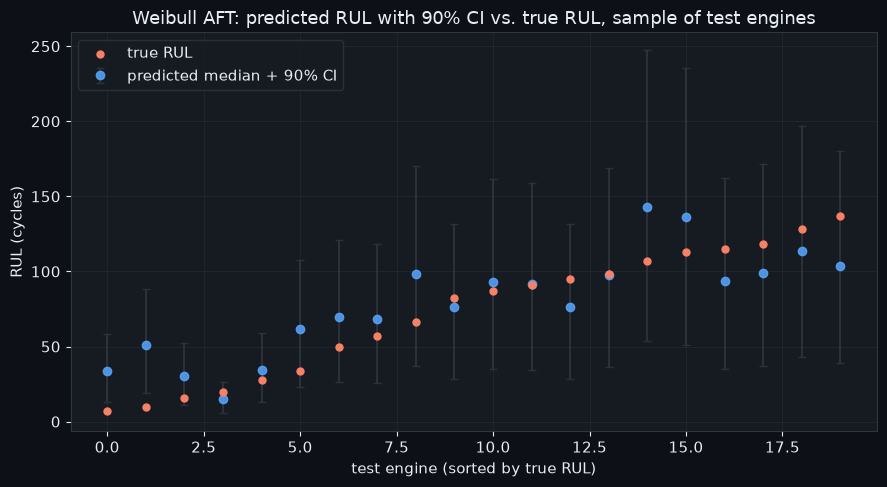

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
sample = predictions.sort_values("true_rul").reset_index(drop=True).iloc[::5]  # thin for readability
x = np.arange(len(sample))
ax.errorbar(x, sample["pred_median_rul"],
            yerr=[sample["pred_median_rul"] - sample["pred_90ci_low"],
                  sample["pred_90ci_high"] - sample["pred_median_rul"]],
            fmt="o", color=plotting.C0, ecolor=plotting.GRID, capsize=3, alpha=0.85,
            label="predicted median + 90% CI")
ax.scatter(x, sample["true_rul"], color=plotting.C1, zorder=5, label="true RUL", s=25)
ax.set_xlabel("test engine (sorted by true RUL)")
ax.set_ylabel("RUL (cycles)")
ax.set_title("Weibull AFT: predicted RUL with 90% CI vs. true RUL, sample of test engines")
ax.legend()
plt.tight_layout()
plt.show()

## Note: predictions are not capped at 125

Training durations were capped at `CAP=125` (see `docs/project_brief.md`
Section 4 for why), but the fitted Weibull distribution is continuous and
unbounded -- nothing stops `predict_percentile` from returning values well
above 125 for engines that look early-life/healthy, and the table above
shows exactly that for several units. This is expected and correct, not a
bug: the cap only affects which *label* the model was trained to match for
already-degrading engines, not the model's own output range. It's called
out here because it's an easy thing to assume the model respects without
checking.

## Summary

- The hand-derived Weibull survival/hazard/log-likelihood was validated to
  within numerical tolerance against `lifelines.WeibullFitter` on real
  C-MAPSS data -- both the failure term and (on a censored version of the
  labels) the censoring term.
- The wear-out claim is tested on per-engine lifetimes (Section 4), not on
  the row-level label distribution, whose shape mostly reflects how the
  labels are constructed.
- Held-out concordance index is a little below Cox PH's from Phase 3 --
  useful context for Phase 6, where the models are compared side by side.
- The 90% interval's empirical coverage on the full FD001 test set gives an
  early read on calibration; Phase 6 compares coverage across models, and
  Phase 14 (notebook 12) checks it by subgroup.
